# Jogo patológico na atenção primária (SISAB)

A atenção primária (UBS, equipes de Saúde da Família) é a porta de entrada do SUS. Este notebook olha os **atendimentos
individuais** registrados no SISAB com diagnóstico de jogo patológico (CID **F63.0**) e compara com outros diagnósticos
de saúde mental e com o CAPS.

**Dados:** `uv run python -m src.saude_mental.sisab_aps`, relatório público de produção do SISAB, de jan/2018 a set/2026,
por mês, para o Brasil, também por sexo e por faixa etária (recortes separados, não cruzados).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import polars as pl

from src.config import CHOQUES, PANDEMIA, pasta

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:.1f}".format)

aps = pl.read_parquet(pasta("atencao_primaria") / "sisab_aps.parquet").with_columns(pl.col("cmp").str.to_date("%Y%m").alias("data"))
CPI = ("2024-11-12", "2025-06-12")


def marcar(ax):
    ini, fim = pl.Series(PANDEMIA).str.to_date(); ax.axvspan(ini, fim, color="gray", alpha=0.15, lw=0)
    a, b = pl.Series(CPI).str.to_date(); ax.axvspan(a, b, color="#6250d6", alpha=0.12, lw=0)
    for i, (d, rot) in enumerate(CHOQUES.items(), 1):
        x = pl.Series([d]).str.to_date()[0]
        ax.axvline(x, color="crimson", ls="--", lw=0.8, alpha=0.7)
        ax.text(x, 1.0, f" {i}", va="top", fontsize=8, color="crimson", transform=ax.get_xaxis_transform())

print(aps["data"].min(), "a", aps["data"].max(), "|", aps["grupo"].n_unique(), "diagnósticos |", aps.height, "linhas")

2018-01-01 a 2026-09-01 | 15 diagnósticos | 14175 linhas


## Decisões

**Atendimentos, não pessoas.** O SISAB conta cada atendimento em que o problema foi registrado. Uma pessoa atendida
três vezes conta três. Por isso os números não se comparam diretamente com os do CAPS, que contam pessoas.

**O sistema cresceu.** O e-SUS APS foi implantado aos poucos, e o registro de diagnósticos ficou mais completo com o
tempo: até a esquizofrenia, que não deveria mudar com as apostas, triplicou de 2018 a 2026. Para separar o crescimento
do jogo do crescimento do sistema, usamos uma **referência**: a soma dos atendimentos de depressão (F32–F33), ansiedade
(F41), estresse (F43), álcool (F10) e esquizofrenia (F20). A medida principal é **jogo patológico por 10 mil
atendimentos de referência**.

**CID, não CIAP.** O jogo patológico só tem código na CID-10 (F63.0). A CIAP-2, também usada na atenção primária, não tem
código específico para jogo. Os diagnósticos registrados só em CIAP ficam de fora da contagem do jogo.

**Meses recentes.** Os dados vão até set/2026. Não há queda nos últimos meses, que seria o sinal de envio incompleto,
mas eles ainda podem ser revisados. Set/2026 inclui os primeiros dias depois da MP 1.394 (25/09).

**Menores de idade.** Há atendimentos com F63.0 em menores de 18 anos, que não podem apostar legalmente. Parte pode ser
uso excessivo de jogos eletrônicos registrado com o código de jogo patológico. Mostramos a faixa separada.

In [2]:
tot = aps.filter(pl.col("recorte") == "total")
REF = ["depressao_cid", "depressao_rec_cid", "ansiedade_cid", "estresse_cid", "alcool_cid", "esquizofrenia_cid"]
mens = (tot.group_by("data").agg(pl.col("atendimentos").filter(pl.col("grupo") == "jogo_cid").sum().alias("jogo"),
                                 pl.col("atendimentos").filter(pl.col("grupo").is_in(REF)).sum().alias("referencia"))
        .with_columns((pl.col("jogo") / pl.col("referencia") * 1e4).alias("por_10mil")).sort("data"))
anual = (mens.with_columns(pl.col("data").dt.year().alias("ano")).group_by("ano")
         .agg((pl.col("jogo").sum() / pl.len()).alias("jogo por mês"), (pl.col("referencia").sum() / pl.len()).alias("referência por mês"),
              (pl.col("jogo").sum() / pl.col("referencia").sum() * 1e4).alias("jogo por 10 mil"), pl.len().alias("meses")).sort("ano"))
anual.to_pandas().set_index("ano")

,jogo por mês,referência por mês,jogo por 10 mil,meses
ano,,,,
2018,10.8,57376.9,1.9,12
2019,11.3,67002.8,1.7,12
2020,9.2,75819.0,1.2,12
2021,15.4,95866.2,1.6,12
2022,19.0,111277.8,1.7,12
2023,58.0,141959.2,4.1,12
2024,119.4,157545.0,7.6,12
2025,285.2,187646.3,15.2,12
2026,610.7,229688.9,26.6,9


## 1. Série mensal

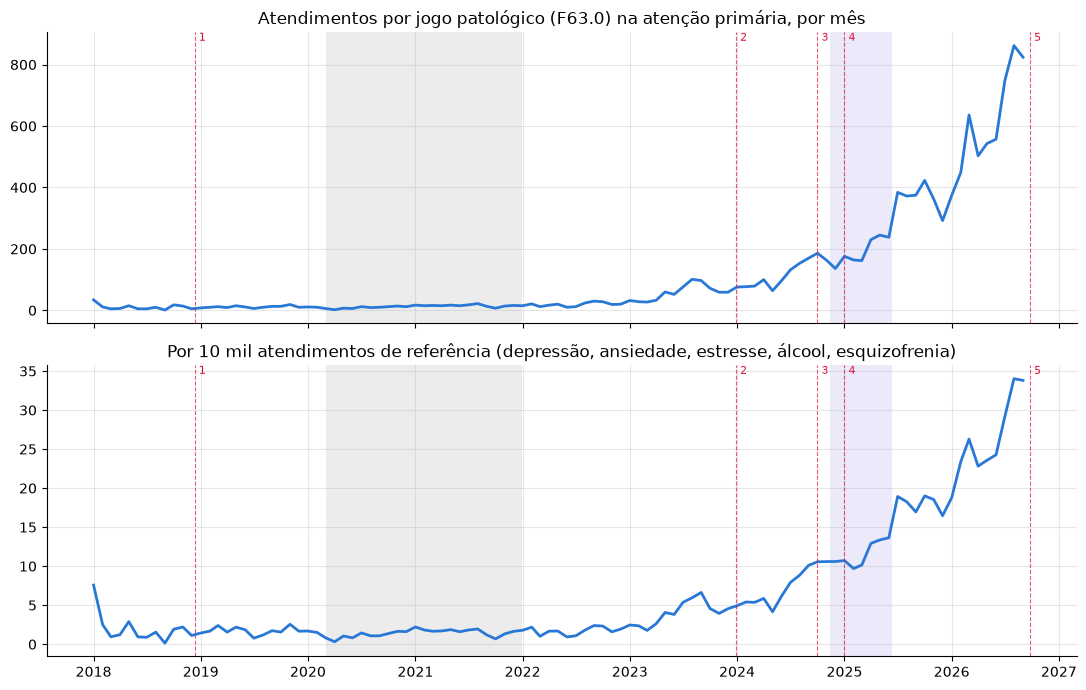

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(mens["data"], mens["jogo"], color="#2a78d6", lw=2); axes[0].set_title("Atendimentos por jogo patológico (F63.0) na atenção primária, por mês")
axes[1].plot(mens["data"], mens["por_10mil"], color="#2a78d6", lw=2); axes[1].set_title("Por 10 mil atendimentos de referência (depressão, ansiedade, estresse, álcool, esquizofrenia)")
for ax in axes: marcar(ax)
plt.tight_layout()

Faixa cinza: pandemia. Faixa lilás: CPI das Bets (nov/2024–jun/2025). Linhas vermelhas: marcos regulatórios.

## 2. Cresceu mais que os outros diagnósticos?

Índice de atendimentos (média de 2022 = 100). Escala logarítmica, para caberem crescimentos muito diferentes.

Text(0.5, 1.0, 'Atendimentos na atenção primária por diagnóstico, média móvel de 3 meses')

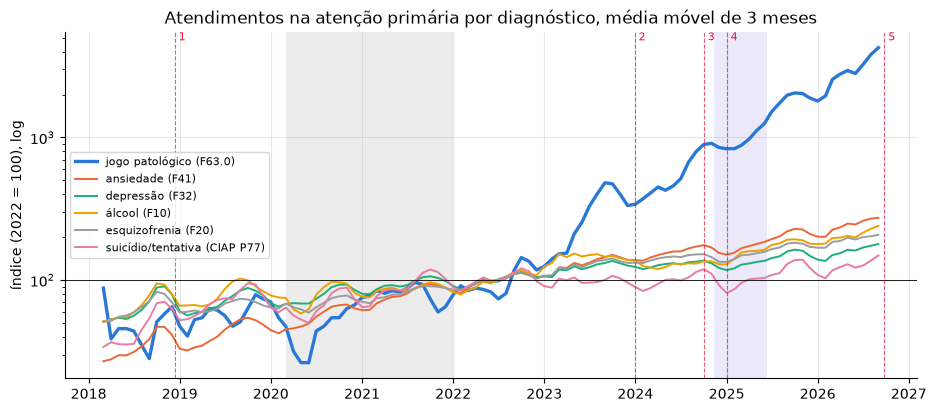

In [4]:
ix = tot.filter(pl.col("grupo").is_in(["jogo_cid", "ansiedade_cid", "depressao_cid", "alcool_cid", "esquizofrenia_cid", "suicidio_tentativa_ciap"]))
base = ix.filter(pl.col("data").dt.year() == 2022).group_by("grupo").agg(pl.col("atendimentos").mean().alias("b"))
ix = ix.join(base, on="grupo").with_columns((pl.col("atendimentos") / pl.col("b") * 100).alias("indice")).sort("data")
rot = {"jogo_cid": "jogo patológico (F63.0)", "ansiedade_cid": "ansiedade (F41)", "depressao_cid": "depressão (F32)",
       "alcool_cid": "álcool (F10)", "esquizofrenia_cid": "esquizofrenia (F20)", "suicidio_tentativa_ciap": "suicídio/tentativa (CIAP P77)"}
fig, ax = plt.subplots(figsize=(11, 4.5))
for g, cor in zip(rot, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#9a9c9e", "#e87ba4"]):
    d = ix.filter(pl.col("grupo") == g)
    ax.plot(d["data"], d["indice"].rolling_mean(3), label=rot[g], color=cor, lw=2.4 if g == "jogo_cid" else 1.4)
ax.set_yscale("log"); ax.axhline(100, color="k", lw=0.6); marcar(ax); ax.legend(fontsize=8); ax.set_ylabel("índice (2022 = 100), log")
ax.set_title("Atendimentos na atenção primária por diagnóstico, média móvel de 3 meses")

In [5]:
cresc = (tot.with_columns(pl.col("data").dt.year().alias("ano")).filter(pl.col("ano").is_in([2022, 2025]))
         .group_by("grupo", "ano").agg(pl.col("atendimentos").mean()).pivot(on="ano", index="grupo", values="atendimentos")
         .with_columns((pl.col("2025") / pl.col("2022")).alias("razão 2025/2022")).sort("razão 2025/2022", descending=True))
cresc.to_pandas().set_index("grupo")

,2022,2025,razão 2025/2022
grupo,,,
jogo_cid,19.0,285.2,15.0
drogas_ciap,3228.7,7098.8,2.2
ansiedade_cid,52149.5,101963.8,2.0
alcool_cid,1668.9,2880.2,1.7
esquizofrenia_cid,20530.8,33739.5,1.6
alcool_ciap,7829.6,11806.2,1.5
sensacao_ansiedade_ciap,149579.9,224671.2,1.5
estresse_cid,558.1,820.9,1.5
depressao_cid,23690.9,33803.3,1.4


## 3. Perfil: sexo e idade

In [6]:
def perfil(recorte, anos):
    d = (aps.filter((pl.col("recorte") == recorte) & pl.col("data").dt.year().is_in(anos))
         .group_by("grupo", "valor").agg(pl.col("atendimentos").sum()))
    d = d.with_columns((pl.col("atendimentos") / pl.col("atendimentos").sum().over("grupo") * 100).alias("%"))
    return d.filter(pl.col("grupo").is_in(["jogo_cid", "ansiedade_cid", "depressao_cid", "alcool_cid"])).pivot(on="grupo", index="valor", values="%").sort("valor")

print("% de mulheres e homens, 2025–2026"); display(perfil("sexo", [2025, 2026]).to_pandas().set_index("valor"))
print("% por faixa etária, 2025–2026"); display(perfil("faixa", [2025, 2026]).to_pandas().set_index("valor"))

% de mulheres e homens, 2025–2026


,alcool_cid,jogo_cid,ansiedade_cid,depressao_cid
valor,,,,
F,19.6,47.4,76.3,78.8
M,80.4,52.6,23.7,21.2


% por faixa etária, 2025–2026


,alcool_cid,ansiedade_cid,depressao_cid,jogo_cid
valor,,,,
0-17,0.6,8.9,4.6,5.5
18-24,2.1,8.7,5.9,15.0
25-34,9.7,15.5,11.2,39.0
35-44,21.8,18.5,16.0,26.6
45-59,41.4,26.2,30.5,11.2
60+,24.5,22.2,31.7,2.8


In [7]:
sx = (aps.filter((pl.col("recorte") == "sexo") & (pl.col("grupo") == "jogo_cid")).with_columns(pl.col("data").dt.year().alias("ano"))
      .group_by("ano", "valor").agg(pl.col("atendimentos").sum()).pivot(on="valor", index="ano", values="atendimentos").sort("ano")
      .with_columns((pl.col("F") / (pl.col("F") + pl.col("M")) * 100).alias("% mulheres")))
sx.to_pandas().set_index("ano")

,F,M,% mulheres
ano,,,
2018,54,75,41.9
2019,42,93,31.1
2020,36,75,32.4
2021,41,144,22.2
2022,50,178,21.9
2023,273,423,39.2
2024,661,772,46.1
2025,1592,1831,46.5
2026,2634,2862,47.9


## 4. Atenção primária × CAPS: quem subiu primeiro?

Índice com a média de 2022 = 100, para as duas redes na mesma escala. CAPS: pessoas distintas com F63.0 por mês (até
jun/2026). Atenção primária: atendimentos com F63.0 por mês (até set/2026).

,APS,CAPS
ano,,
2018,56.6,46.0
2019,59.6,69.5
2020,48.7,55.6
2021,81.1,84.5
2022,100.0,100.0
2023,305.3,152.3
2024,628.5,253.1
2025,1501.3,701.3
2026,3214.0,1227.6


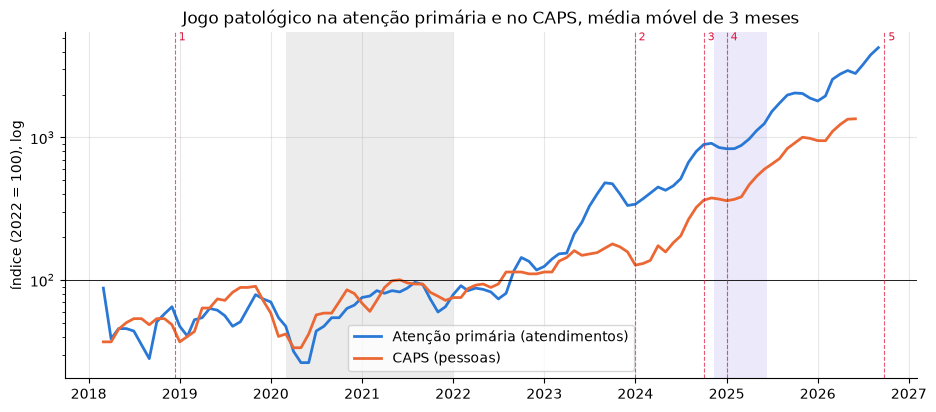

In [8]:
caps = (pl.read_parquet(pasta("caps") / "sia_f63_registros.parquet")
        .filter(((pl.col("CIDPRI") == "F630") | (pl.col("CIDASSOC") == "F630")) & pl.col("cmp").is_between(pl.lit("201801"), pl.lit("202606")))
        .group_by("cmp").agg(pl.col("id").n_unique().alias("caps")).with_columns(pl.col("cmp").str.to_date("%Y%m").alias("data")))
comp = mens.select("data", pl.col("jogo").alias("aps")).join(caps.select("data", "caps"), on="data", how="left").sort("data")
b = comp.filter(pl.col("data").dt.year() == 2022).select(pl.col("aps", "caps").mean())
comp = comp.with_columns((pl.col("aps") / b["aps"][0] * 100).alias("APS"), (pl.col("caps") / b["caps"][0] * 100).alias("CAPS"))
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(comp["data"], comp["APS"].rolling_mean(3), label="Atenção primária (atendimentos)", color="#2a78d6", lw=2)
ax.plot(comp["data"], comp["CAPS"].rolling_mean(3), label="CAPS (pessoas)", color="#eb6834", lw=2)
ax.set_yscale("log"); ax.axhline(100, color="k", lw=0.6); marcar(ax); ax.legend(); ax.set_ylabel("índice (2022 = 100), log")
ax.set_title("Jogo patológico na atenção primária e no CAPS, média móvel de 3 meses")
an = comp.with_columns(pl.col("data").dt.year().alias("ano")).group_by("ano").agg(pl.col("APS", "CAPS").mean()).sort("ano")
an.to_pandas().set_index("ano")

## Leitura

**1. O jogo patológico disparou na atenção primária, bem além do crescimento do sistema.** Os atendimentos com F63.0
passaram de ~19 por mês em 2022 para ~285 em 2025 e ~611 em 2026 (até setembro). Mesmo comparando com a referência
(outros diagnósticos de saúde mental, que também cresceram com a expansão do registro), a taxa foi de 1,7 para 15,2 por
10 mil atendimentos entre 2022 e 2025, cerca de 9×, e chegou a 26,6 em 2026. Ansiedade, depressão, álcool e
esquizofrenia cresceram entre 1,4× e 2× no mesmo período, no ritmo da expansão do sistema.

**2. A atenção primária viu antes, e mais forte, do que o CAPS.** Em 2023, os atendimentos por jogo na atenção
primária já tinham triplicado em relação a 2022, enquanto no CAPS o aumento era de 50%. Em 2025, foram 15× contra 7×.
Isso é coerente com a atenção primária ser a porta de entrada: parte dos casos chega primeiro à UBS e depois é
encaminhada ao CAPS.

**3. É um problema de adultos jovens, e cada vez mais de mulheres.** 39% dos atendimentos por jogo são de pessoas de 25 a
34 anos e 27% de 35 a 44, um perfil bem mais jovem que o da ansiedade e da depressão, concentradas a partir dos 45. As
mulheres eram 22% dos atendimentos por jogo em 2021–2022 e passaram a 46–48% em 2024–2026. É o mesmo movimento visto no
CAPS.

**4. Suicídio e tentativa de suicídio (CIAP P77) não mudaram** (1,1× entre 2022 e 2025), coerente com o SIM.

**Limites:** atendimentos não são pessoas; o jogo só tem código na CID-10, então o que for registrado apenas em CIAP fica
de fora; 5,5% dos atendimentos por F63.0 são de menores de 18 anos, e parte pode ser uso de jogos eletrônicos registrado
com esse código; os meses de 2026 ainda podem ser revisados.